<a href="https://colab.research.google.com/github/GavrilLaura/PMP-2026/blob/main/Lab04/pmp_lab4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Exerciţiu laborator 4**
##**Reţele Markov**

Considerăm o reţea de Markov de dimensiune mică care descrie distribuţia probabilităţilor pentru 5 variabile discrete binare (cu valorile 0 şi 1): A1, A2, A3, A4 şi A5. Relaţiile de independenţă condiţionată dintre aceste variabile sunt descrise de următoarele conexiuni: A1 este conectat cu A2 şi A3, A2 este conectat cu A4 şi A5, A3 este conectat cu A4, iar A4 este conectat cu A5. Se cunoaşte următoarea distribuţie a energiei pentru clicile maximale ale modelului:

**a)** Vizualizaţi în pyAgrum graful reţelei Markov, iar apoi determinaţi clicile modelului.

**b)** Determinaţi probabilitatea comună a celor 5 variabile şi deduceţi stările de probabilitate maximă pentru acestea.

**c)** Explicaţi cum aţi modifica funcţiile de potenţial pentru a modela modelul Ising, în care sunt favorizate perechile
de vecini care au aceeaşi valoare.

In [1]:
!pip install pyagrum -q

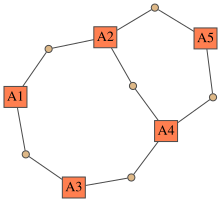

In [2]:
# a)

import itertools
import numpy as np
import pyagrum as gum
import pyagrum.lib.notebook as gnb

VARS = ["A1", "A2", "A3", "A4", "A5"]
EDGES = [("A1", "A2"), ("A1", "A3"), ("A2", "A4"), ("A2", "A5"), ("A3", "A4"), ("A4", "A5")]

mrf = gum.MarkovRandomField()
for v in VARS:
    mrf.add(gum.LabelizedVariable(v, v, 2))

for x, y in EDGES:
    mrf.addFactor([x, y])

gnb.showMRF(mrf)



In [3]:
neighbors = {}
for v in VARS:
    neighbors[v] = set()

for x, y in EDGES:
    neighbors[x].add(y)
    neighbors[y].add(x)

def is_clique(nodes):
    nodes = list(nodes)
    for i in range(len(nodes)):
        for j in range(i + 1, len(nodes)):
            a = nodes[i]
            b = nodes[j]
            if b not in neighbors[a]:
                return False
    return True

all_cliques = []
for k in range(1, len(VARS) + 1):
    for subset in itertools.combinations(VARS, k):
        if is_clique(subset):
            all_cliques.append(set(subset))

max_cliques = []
for c in all_cliques:
    is_maximal = True
    for d in all_cliques:
        if c < d:
            is_maximal = False
            break
    if is_maximal:
        max_cliques.append(c)

print("\nClici maximale:")
for c in max_cliques:
    print("  ", sorted(c))


Clici maximale:
   ['A1', 'A2']
   ['A1', 'A3']
   ['A3', 'A4']
   ['A2', 'A4', 'A5']


In [4]:
# b) Probabilitatea comuna si starea de probabilitate maxima
import itertools
import math

beta = 1
clici = [["A1", "A2"], ["A1", "A3"], ["A3", "A4"], ["A2", "A4", "A5"]]

def potential(clica, stare):
    # suma produselor a_i * a_j pentru toate perechile din clica
    suma = 0
    for i in range(len(clica)):
        for j in range(i + 1, len(clica)):
            suma = suma + stare[clica[i]] * stare[clica[j]]
    return math.exp(beta * suma)

configuratii = []
ponderi = []

# toate cele 2^5 = 32 de configuratii
for valori in itertools.product([0, 1], repeat=5):
    stare = {}
    for k in range(5):
        stare[VARS[k]] = valori[k]

    produs = 1
    for c in clici:
        produs = produs * potential(c, stare)

    configuratii.append(valori)
    ponderi.append(produs)

Z = sum(ponderi)
print("Z =", round(Z, 2))

pondere_max = max(ponderi)
print("Starea (starile) de probabilitate maxima:")
for i in range(len(configuratii)):
    if ponderi[i] == pondere_max:
        print(configuratii[i], " P =", round(ponderi[i] / Z, 4))

Z = 706.28
Starea (starile) de probabilitate maxima:
(1, 1, 1, 1, 1)  P = 0.5712


In [5]:
# c) Modelul Ising: favorizam vecinii cu aceeasi valoare
def potential_ising(clica, stare):
    # numaram perechile din clica in care vecinii au aceeasi valoare
    egale = 0
    for i in range(len(clica)):
        for j in range(i + 1, len(clica)):
            if stare[clica[i]] == stare[clica[j]]:
                egale = egale + 1
    return math.exp(beta * egale)

configuratii = []
ponderi = []

for valori in itertools.product([0, 1], repeat=5):
    stare = {}
    for k in range(5):
        stare[VARS[k]] = valori[k]

    produs = 1
    for c in clici:
        produs = produs * potential_ising(c, stare)

    configuratii.append(valori)
    ponderi.append(produs)

Z = sum(ponderi)
print("Z =", round(Z, 2))

pondere_max = max(ponderi)
print("Starea (starile) de probabilitate maxima:")
for i in range(len(configuratii)):
    if ponderi[i] == pondere_max:
        print(configuratii[i], " P =", round(ponderi[i] / Z, 4))

Z = 1539.88
Starea (starile) de probabilitate maxima:
(0, 0, 0, 0, 0)  P = 0.262
(1, 1, 1, 1, 1)  P = 0.262
